/home/mluser/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /home/mluser/venv/bin/python
User: mluser
CWD: /home/mluser
CWD writable: True
pyarrow уже импортирован: True
График будет сохранён в: /home/mluser/pii_ner_distribution.png

Загрузка датасета...


Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


DatasetDict({
    train: Dataset({
        features: ['text', 'entity_starts', 'entity_ends', 'entity_labels', 'entity_texts', 'source', 'noisy'],
        num_rows: 4786
    })
    test: Dataset({
        features: ['text', 'entity_starts', 'entity_ends', 'entity_labels', 'entity_texts', 'source', 'noisy'],
        num_rows: 532
    })
})

Всего объектов (train+test): 5318
Колонки: ['text', 'entity_starts', 'entity_ends', 'entity_labels', 'entity_texts', 'source', 'noisy']

--- Частота типов сущностей ---
ip                            4989
first_name                    3047
name                          3043
date                          2774
address_city                  2448
last_name                     2121
mobile_phone                  2048
address                       1889
address_street                1784
document_number               1376
email                         1349
middle_name                   1055
organization                  1023
address_house                  770

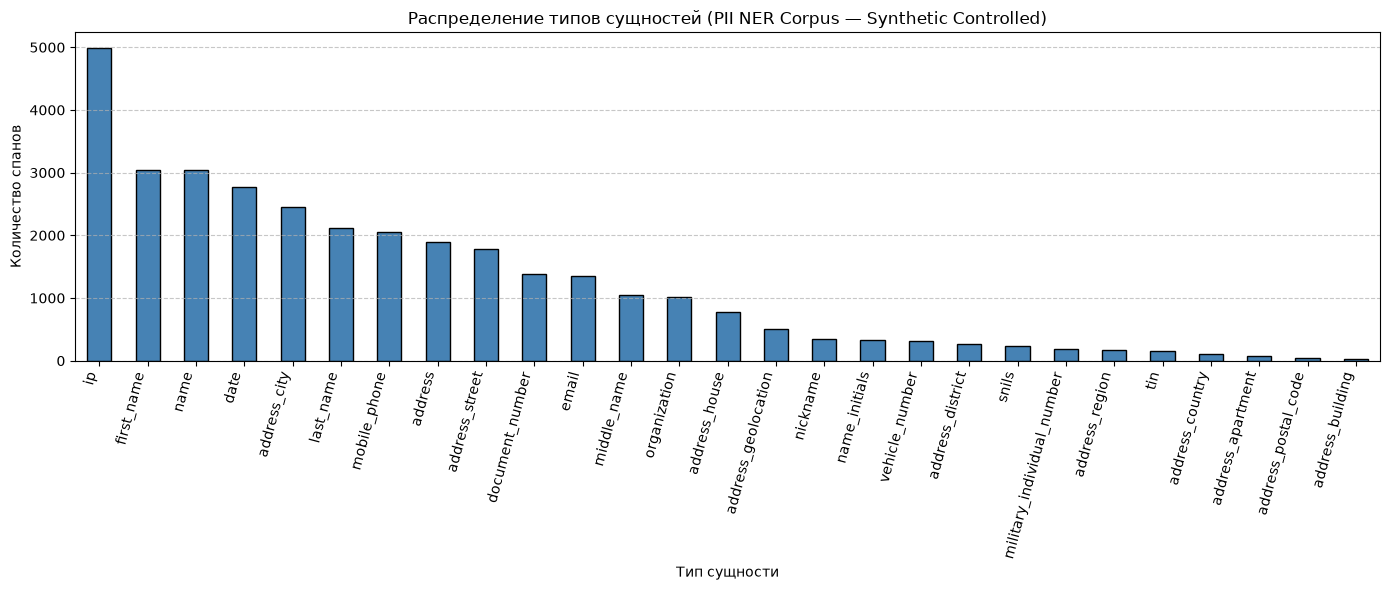


--- Документы с ПДн / без ПДн ---
has_pii
True     4787
False     531
Name: count, dtype: int64
Доля без ПДн (негативные): 9.98%

--- Распределение числа сущностей на документ ---
num_entities
0     531
1     487
2     429
3     453
4     464
5     460
6     444
7     405
8     291
9     279
10    191
11    160
12    146
13     99
14     94
15     75
16     62
17     52
18     39
19     36
20     31
21     18
22     14
23     10
24     12
25      6
26     12
27      4
28      1
29      1
30      3
32      2
33      1
36      1
40      1
42      2
44      1
48      1
Name: count, dtype: int64

ИТОГИ ДЛЯ ОТЧЁТА
Датасет: PII NER Corpus — Synthetic Controlled
Объектов всего: 5318 (train=4786, test=532)
Типов сущностей: 27
Всего спанов: 32500
Разброс по классам: 28 — 4989 (отношение max/min = 178.18)
Документы с ПДн: 90.02%
Документы без ПДн: 9.98%
Среднее число сущностей на документ: 6.11

Топ-5 частых классов:
ip              4989
first_name      3047
name            3043
date           

In [1]:
# -*- coding: utf-8 -*-
"""
Проверка сбалансированности PII NER Corpus — Synthetic Controlled.
Классы = типы сущностей (entity_labels).
"""

# ⚠️ Строго ДО импорта pyarrow/pandas — CPU VM без AVX/AVX2/FMA
import os
os.environ["ARROW_USER_SIMD_LEVEL"] = "NONE"

import sys
import getpass
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

# ---------------------------------------------------------
# 0. Диагностика окружения
# ---------------------------------------------------------
print("Python:", sys.executable)
print("User:", getpass.getuser())
print("CWD:", os.getcwd())
print("CWD writable:", os.access(os.getcwd(), os.W_OK))
print("pyarrow уже импортирован:", "pyarrow" in sys.modules)

# Куда сохранять график — всегда в домашний каталог пользователя ядра
out_png = os.path.expanduser("~/pii_ner_distribution.png")
print("График будет сохранён в:", out_png)

# ---------------------------------------------------------
# 1. Загрузка датасета
# ---------------------------------------------------------
print("\nЗагрузка датасета...")
ds = load_dataset("scanpatch/pii-ner-corpus-synthetic-controlled")
print(ds)

# Объединяем train и test для общей картины
df_train = ds["train"].to_pandas()
df_test = ds["test"].to_pandas()
df = pd.concat([df_train, df_test], ignore_index=True)
print(f"\nВсего объектов (train+test): {len(df)}")
print(f"Колонки: {list(df.columns)}")

# ---------------------------------------------------------
# 2. Распределение классов (типов сущностей)
# ---------------------------------------------------------
all_labels = []
for labels in df["entity_labels"]:
    if labels is None:
        continue
    # На случай, если пришёл не list, а numpy-массив или строка
    try:
        all_labels.extend(labels)
    except TypeError:
        all_labels.append(labels)

label_counts = pd.Series(all_labels).value_counts()
print("\n--- Частота типов сущностей ---")
print(label_counts)
print(f"\nВсего спанов: {label_counts.sum()}")
print(f"Уникальных типов: {len(label_counts)}")
print(f"Min / Max на тип: {label_counts.min()} / {label_counts.max()}")
print(f"Отношение max/min: {label_counts.max() / label_counts.min():.2f}")

# ---------------------------------------------------------
# 3. График распределения классов
# ---------------------------------------------------------
plt.figure(figsize=(14, 6))
label_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Распределение типов сущностей (PII NER Corpus — Synthetic Controlled)")
plt.xlabel("Тип сущности")
plt.ylabel("Количество спанов")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

# Сохраняем в домашний каталог (гарантированно доступен для записи)
try:
    plt.savefig(out_png, dpi=150, bbox_inches="tight")
    print(f"\nГрафик сохранён: {out_png}")
except PermissionError as e:
    # Запасной вариант — во временный каталог
    fallback = "/tmp/pii_ner_distribution.png"
    plt.savefig(fallback, dpi=150, bbox_inches="tight")
    print(f"\nНе удалось сохранить в {out_png} ({e}). "
          f"Сохранено в {fallback}")

plt.show()

# ---------------------------------------------------------
# 4. Наличие негативных примеров (без сущностей)
# ---------------------------------------------------------
df["num_entities"] = df["entity_labels"].apply(
    lambda x: 0 if x is None else len(x)
)
df["has_pii"] = df["num_entities"] > 0

print("\n--- Документы с ПДн / без ПДн ---")
print(df["has_pii"].value_counts())
print(f"Доля без ПДн (негативные): {(~df['has_pii']).mean() * 100:.2f}%")

print("\n--- Распределение числа сущностей на документ ---")
print(df["num_entities"].value_counts().sort_index())

# ---------------------------------------------------------
# 5. Итоговая сводка для отчёта
# ---------------------------------------------------------
print("\n" + "=" * 60)
print("ИТОГИ ДЛЯ ОТЧЁТА")
print("=" * 60)
print(f"Датасет: PII NER Corpus — Synthetic Controlled")
print(f"Объектов всего: {len(df)} (train={len(df_train)}, test={len(df_test)})")
print(f"Типов сущностей: {len(label_counts)}")
print(f"Всего спанов: {label_counts.sum()}")
print(f"Разброс по классам: {label_counts.min()} — {label_counts.max()} "
      f"(отношение max/min = {label_counts.max()/label_counts.min():.2f})")
print(f"Документы с ПДн: {df['has_pii'].mean()*100:.2f}%")
print(f"Документы без ПДн: {(~df['has_pii']).mean()*100:.2f}%")
print(f"Среднее число сущностей на документ: {df['num_entities'].mean():.2f}")
print("=" * 60)

print("\nТоп-5 частых классов:")
print(label_counts.head())
print("\nТоп-5 редких классов:")
print(label_counts.tail())